<a href="https://colab.research.google.com/github/LexieLyu37/also-cracker/blob/main/04_ML_Logistic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CID: 02392139
Username: kl3323

We will use logistic regression as a binary classifier between Setosa vs other classes (verginica and versicolor grouped together). Here we say that data points with features that result in output probabilities closer to 0 are likely Setosa, while values closer to 1 are likely not Setosa. For simplicity, we will consider two features, petal length and sepal length, which can be visualised in a 2D plot.

In [193]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
import pandas as pd

In [194]:
iris = datasets.load_iris()

In [195]:
iris_data = pd.DataFrame(data=iris['data'],columns=iris['feature_names'])
iris_data["target"] = iris['target']

In [196]:
iris_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [197]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

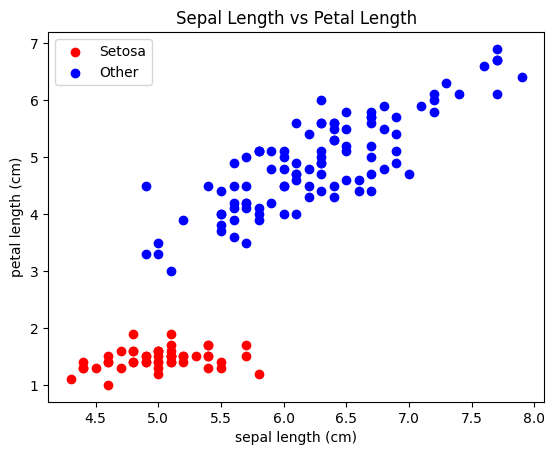

In [198]:
# Target labels are the index in iris.target_names
labels = iris_data.iloc[:,4]

# Setosa is assigned label 0, while all other classes will have a label of 1
y = np.where(labels == 0, 0, 1)

# Consider only two features - sepal length (column 0) and petal length (column 2)
# Bias term (intercept) is added to each data point (row)
X = iris_data.iloc[:,[0,2]]
intercept = np.ones((X.shape[0], 1))
X = np.concatenate((intercept, X), axis=1)

# Plot features in 2D plot - sepal length (x-axis) vs petal length (y-axis)
feat1, feat2 = 'sepal length (cm)', 'petal length (cm)'
X_target = iris_data[iris_data.target==0]
X_other = iris_data[iris_data.target!=0]

plt.scatter(X_target[feat1],X_target[feat2],color='red',marker='o',label="Setosa")
plt.scatter(X_other[feat1],X_other[feat2],color='blue',marker='o',label='Other')
plt.title("Sepal Length vs Petal Length")
plt.xlabel(feat1)
plt.ylabel(feat2)
plt.legend(loc='upper left')
plt.show()

In [199]:
def sigmoid(z):
    # Sigmoid function
    return 1 / (1 + np.exp(-z))

In [200]:
def cost(Y, y):
    # log-loss or Binary Cross Entropy (BCE)
    eps = 1e-15 # to avoid numerical error at log(0)
    return (-y * np.log(Y+eps) - (1 - y) * np.log(1 - Y + eps)).mean()

In [201]:
def plot_cost(loss):
    # Function for plotting the cost vs iterations.
    plt.plot(range(1, len(loss) + 1), loss)
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    # plt.savefig('plot.pdf')
    plt.show()

In [202]:
def predict(X, W):
    # Function for predicting on test data (see Task 1)
    prediction = sigmoid(np.dot(X, W))
    return prediction.round()

In [203]:
def fit(alpha, num_iter, X, y):
    # weights initialization
    W = np.zeros(X.shape[1])
    loss_list = []
    for i in range(num_iter):
        # Feed forward
        z = np.dot(X, W)
        Y = sigmoid(z)
        # Gradient
        W += alpha * (np.dot(X.T, (y-Y)) / y.size)
        loss = cost(Y, y)
        loss_list.append(loss)

        if i % 100 == 0:
            print(f'iteration: {i+1} \t', f'cost: {loss} \t', f'weights: {W} \t')
    plot_cost(loss_list)
    # This function will return the final weights as an array
    return W

iteration: 1 	 cost: 0.6931471805599433 	 weights: [0.00166667 0.01253    0.01391667] 	
iteration: 101 	 cost: 0.39716904888478627 	 weights: [-0.05071148 -0.07762237  0.42536019] 	
iteration: 201 	 cost: 0.29984517309777964 	 weights: [-0.10551432 -0.23097319  0.68989714] 	
iteration: 301 	 cost: 0.2382094249373507 	 weights: [-0.14864573 -0.34969591  0.90262115] 	
iteration: 401 	 cost: 0.196815362215292 	 weights: [-0.18374873 -0.44513976  1.07818086] 	
iteration: 501 	 cost: 0.1674853678274873 	 weights: [-0.21316007 -0.52436457  1.22669262] 	
iteration: 601 	 cost: 0.14576052746256243 	 weights: [-0.23838792 -0.5918273   1.3549739 ] 	
iteration: 701 	 cost: 0.12908024748143987 	 weights: [-0.26043675 -0.65044743  1.46769223] 	
iteration: 801 	 cost: 0.11589461609963037 	 weights: [-0.27999968 -0.70221333  1.56813002] 	
iteration: 901 	 cost: 0.1052199140543055 	 weights: [-0.29757115 -0.74852835  1.65866121] 	
iteration: 1001 	 cost: 0.0964055186179073 	 weights: [-0.31351439 -0.7

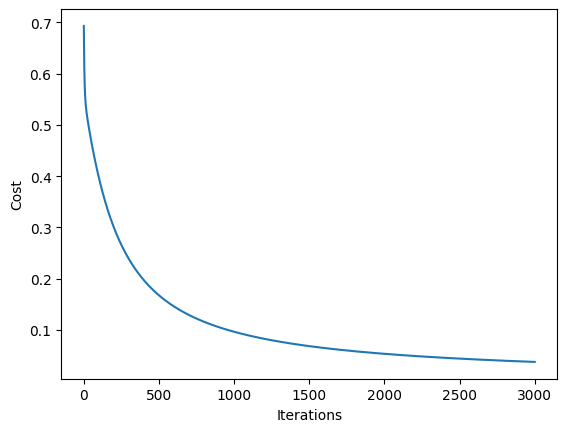

In [204]:
alpha = 0.01
num_iter = 3000
model_weights = fit(alpha, num_iter, X,y)

In [205]:
predictions = predict(X, model_weights)
pred = predictions.astype('int')
true = y.astype('int')

In [206]:
def compute_confusion_matrix(true, pred):

    num_cls = len(np.unique(true)) # Number of classes
    result = np.zeros((num_cls, num_cls))

    for i in range(len(true)):
        result[true[i]][pred[i]] += 1

    return result

conf_matrix = compute_confusion_matrix(true, pred)
print('Confusion matrix result: ')
print(conf_matrix)

diagonal_sum = conf_matrix.trace()
sum_of_all_elements = conf_matrix.sum()
accuracy = diagonal_sum / sum_of_all_elements
print('accuracy = {:0.2f}%'.format(accuracy*100))

Confusion matrix result: 
[[ 50.   0.]
 [  0. 100.]]
accuracy = 100.00%


We use 80% of the data to train the model.
We use the other 20% to test the model.
The model learns from the training data.
The test data is new data for the model.
This shows if the model can work well on new data.
If we use the same data for training and testing, the accuracy may look too high.

In [207]:
# Task 1
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


iteration: 1 	 cost: 0.6931471805599435 	 weights: [0.00166667 0.01260417 0.0139625 ] 	
iteration: 101 	 cost: 0.398733218942356 	 weights: [-0.05167828 -0.07619853  0.42256396] 	
iteration: 201 	 cost: 0.3023544374133587 	 weights: [-0.10755162 -0.22917148  0.68535004] 	
iteration: 301 	 cost: 0.24097249137400378 	 weights: [-0.15172873 -0.34788957  0.89728534] 	
iteration: 401 	 cost: 0.19957682325904566 	 weights: [-0.18781327 -0.44347508  1.07258265] 	
iteration: 501 	 cost: 0.1701552801375902 	 weights: [-0.21813588 -0.52289577  1.22111873] 	
iteration: 601 	 cost: 0.1483112366728467 	 weights: [-0.24420953 -0.59057175  1.34958465] 	
iteration: 701 	 cost: 0.1315079829162113 	 weights: [-0.26704601 -0.64940738  1.46257953] 	
iteration: 801 	 cost: 0.11820467255775945 	 weights: [-0.28734564 -0.70138478  1.56334716] 	
iteration: 901 	 cost: 0.10742069889720404 	 weights: [-0.30560918 -0.74790481  1.65423876] 	
iteration: 1001 	 cost: 0.0985061050343774 	 weights: [-0.32220523 -0.78

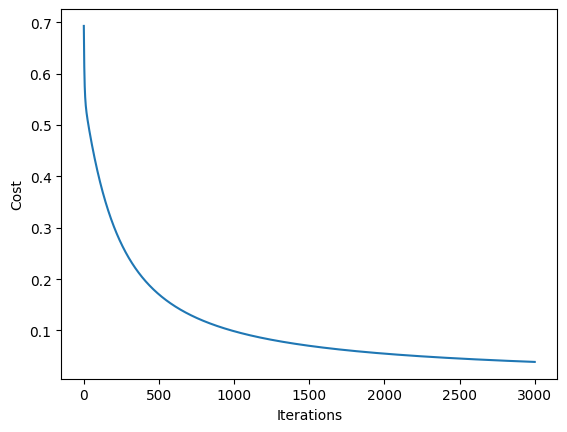

In [208]:
model_weights_train = fit(
    alpha,
    num_iter,
    X_train,
    y_train
)

In [209]:
pred_test = predict(X_test, model_weights_train)
pred_test = pred_test.astype(int)

true_test = np.asarray(y_test).astype(int)

conf_matrix_test = compute_confusion_matrix(true_test, pred_test)

print("Confusion matrix for the test data:")
print(conf_matrix_test)

correct_predictions = np.trace(conf_matrix_test)
total_predictions = conf_matrix_test.sum()
test_accuracy = correct_predictions / total_predictions

print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Confusion matrix for the test data:
[[10.  0.]
 [ 0. 20.]]
Test accuracy: 100.00%


The model was trained with 80% of the data, the remaining 20% was used for testing.
The confusion matrix shows 10 correct predictions for class 0 and 20 correct predictions for class 1.
There were no wrong predictions, so the test accuracy was 100%.

In Task 2, the model is used for two different problems.
First, it classifies Iris-Versicolor against all other flowers.
Second, it classifies Iris-Virginica against all other flowers.
For each problem, the data is divided into training data and testing data.

iteration: 1 	 cost: 0.6931471805599435 	 weights: [-0.00166667 -0.0093875  -0.00437083] 	
iteration: 101 	 cost: 0.6295285933708935 	 weights: [-0.03338031 -0.14718251  0.07593781] 	
iteration: 201 	 cost: 0.6173564335564786 	 weights: [-0.04845279 -0.2069908   0.16672092] 	
iteration: 301 	 cost: 0.6102508770916873 	 weights: [-0.05858271 -0.25329435  0.23593403] 	
iteration: 401 	 cost: 0.6059983280121426 	 weights: [-0.06505662 -0.28956748  0.28938232] 	
iteration: 501 	 cost: 0.6033951861991873 	 weights: [-0.06878916 -0.31829219  0.33112187] 	
iteration: 601 	 cost: 0.6017690108397431 	 weights: [-0.07043877 -0.34126253  0.36402953] 	
iteration: 701 	 cost: 0.6007337583485878 	 weights: [-0.07048705 -0.35979499  0.39018347] 	
iteration: 801 	 cost: 0.6000622713136442 	 weights: [-0.06929193 -0.3748706   0.4111124 ] 	
iteration: 901 	 cost: 0.5996179996998141 	 weights: [-0.06712338 -0.38723084  0.42795956] 	
iteration: 1001 	 cost: 0.5993173638999068 	 weights: [-0.06418768 -0.39

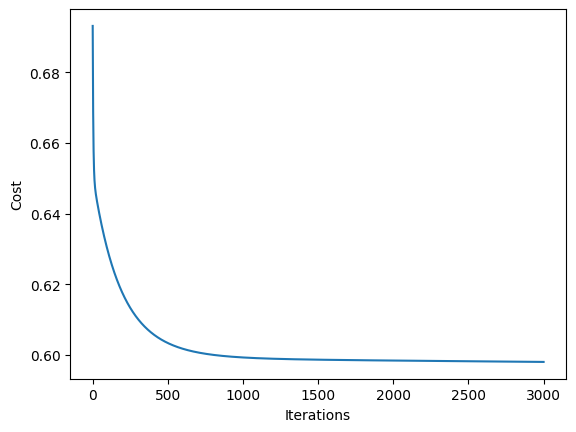

Versicolor weights:
[ 0.04273981 -0.46198275  0.5073652 ]
Versicolor confusion matrix:
[[19.  1.]
 [10.  0.]]
Versicolor test accuracy: 63.33%


In [210]:
# Task 2

y_versicolor = (iris_data["target"] == 1).astype(int).values

X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
    X,
    y_versicolor,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y_versicolor
)

weights_versicolor = fit(
    alpha,
    num_iter,
    X_train_v,
    y_train_v
)

pred_v = predict(X_test_v, weights_versicolor).astype(int)

conf_v = compute_confusion_matrix(y_test_v, pred_v)

accuracy_v = np.trace(conf_v) / conf_v.sum()

print("Versicolor weights:")
print(weights_versicolor)

print("Versicolor confusion matrix:")
print(conf_v)

print(f"Versicolor test accuracy: {accuracy_v * 100:.2f}%")

For Versicolor classification, the final weights were:[0.0427, 0.4620, 0.5074]
The test accuracy was 63.33%. The model made some wrong predictions.
Versicolor is harder to separate from the other flowers.

iteration: 1 	 cost: 0.6931471805599435 	 weights: [-1.66666667e-03 -7.04583333e-03  3.75000000e-05] 	
iteration: 101 	 cost: 0.5524453068932396 	 weights: [-0.08223356 -0.22875256  0.26724875] 	
iteration: 201 	 cost: 0.47990358504503233 	 weights: [-0.14131079 -0.37325085  0.48520203] 	
iteration: 301 	 cost: 0.434421022152828 	 weights: [-0.18995286 -0.48917588  0.65657326] 	
iteration: 401 	 cost: 0.4034141518502336 	 weights: [-0.23155392 -0.58581384  0.79721534] 	
iteration: 501 	 cost: 0.38080918740552827 	 weights: [-0.2682025  -0.66887719  0.91669337] 	
iteration: 601 	 cost: 0.3634497220623468 	 weights: [-0.30122372 -0.74199579  1.02095355] 	
iteration: 701 	 cost: 0.349570460408618 	 weights: [-0.33149224 -0.80756952  1.11384799] 	
iteration: 801 	 cost: 0.33811828527686016 	 weights: [-0.35960783 -0.86724648  1.19797532] 	
iteration: 901 	 cost: 0.3284295718775235 	 weights: [-0.38599616 -0.92219745  1.27515348] 	
iteration: 1001 	 cost: 0.32006639927648384 	 weights: [-0.

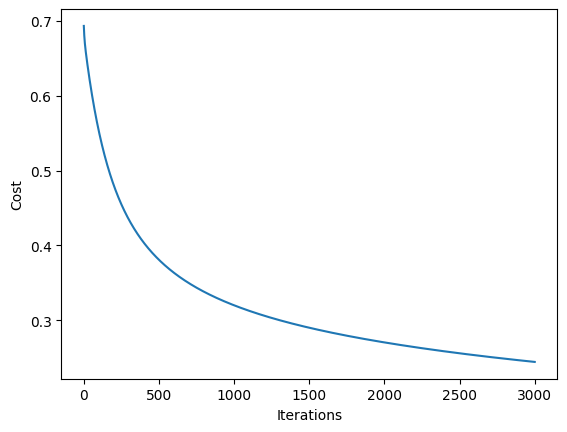

Virginica weights:
[-0.78049476 -1.64342739  2.27965542]
Virginica confusion matrix:
[[19.  1.]
 [ 1.  9.]]
Virginica test accuracy: 93.33%


In [211]:
y_virginica = (iris_data["target"] == 2).astype(int).values

X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
    X,
    y_virginica,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y_virginica
)

weights_virginica = fit(
    alpha,
    num_iter,
    X_train_g,
    y_train_g
)

pred_g = predict(X_test_g, weights_virginica).astype(int)

conf_g = compute_confusion_matrix(y_test_g, pred_g)

accuracy_g = np.trace(conf_g) / conf_g.sum()

print("Virginica weights:")
print(weights_virginica)

print("Virginica confusion matrix:")
print(conf_g)

print(f"Virginica test accuracy: {accuracy_g * 100:.2f}%")

For Virginica classification, the final weights were: [-0.7805, -1.6343, 2.2797]
The test accuracy was 93.33%. The model made only two wrong predictions.Virginica was easier to separate from the other flowers than Versicolor.

In [212]:
# Task 3
learning_rates = [0.0001, 0.01, 0.1, 1, 100]
num_iter_task3 = 3000


def fit_with_loss(alpha_value, num_iter, X_data, y_data):
    weights = np.zeros(X_data.shape[1])
    losses = []

    for _ in range(num_iter):
        probabilities = sigmoid(np.dot(X_data, weights))
        error = y_data - probabilities
        weights += alpha_value * (np.dot(X_data.T, error) / y_data.size)

        probabilities_for_cost = np.clip(probabilities, 1e-15, 1 - 1e-15)
        loss = (-y_data * np.log(probabilities_for_cost)
                - (1 - y_data) * np.log(1 - probabilities_for_cost)).mean()
        losses.append(loss)

    return weights, losses


In [213]:
results_task3 = {}

for alpha_value in learning_rates:
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        weights, losses = fit_with_loss(
            alpha_value, num_iter_task3, X_train, y_train
        )

    predictions = predict(X_test, weights).astype(int)
    true_labels = np.asarray(y_test).astype(int)
    confusion_matrix = compute_confusion_matrix(true_labels, predictions)
    accuracy = np.trace(confusion_matrix) / confusion_matrix.sum()

    results_task3[alpha_value] = {
        "weights": weights,
        "losses": losses,
        "confusion_matrix": confusion_matrix,
        "accuracy": accuracy
    }

    print(f"\nLearning rate alpha = {alpha_value}")
    print("Final weights:", weights)
    print("Confusion matrix:")
    print(confusion_matrix)
    print(f"Test accuracy: {accuracy * 100:.2f}%")



Learning rate alpha = 0.0001
Final weights: [-0.00325586  0.05543532  0.19082736]
Confusion matrix:
[[ 0. 10.]
 [ 0. 20.]]
Test accuracy: 66.67%

Learning rate alpha = 0.01
Final weights: [-0.50608217 -1.24701879  2.66236742]
Confusion matrix:
[[10.  0.]
 [ 0. 20.]]
Test accuracy: 100.00%

Learning rate alpha = 0.1
Final weights: [-0.93281687 -2.28986437  4.88387571]
Confusion matrix:
[[10.  0.]
 [ 0. 20.]]
Test accuracy: 100.00%

Learning rate alpha = 1
Final weights: [-1.41331386 -3.5210379   7.59535726]
Confusion matrix:
[[10.  0.]
 [ 0. 20.]]
Test accuracy: 100.00%

Learning rate alpha = 100
Final weights: [-16.66666667 -40.125       90.375     ]
Confusion matrix:
[[10.  0.]
 [ 0. 20.]]
Test accuracy: 100.00%


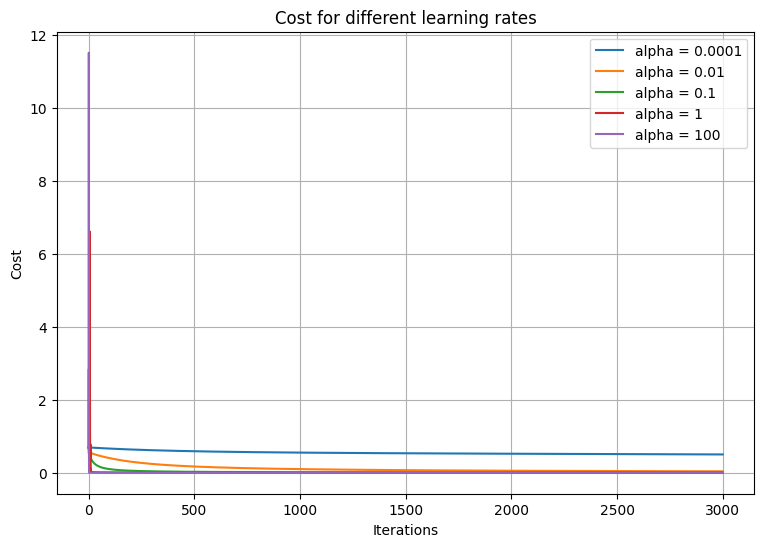

In [214]:
plt.figure(figsize=(9, 6))

for alpha_value in learning_rates:
    losses = results_task3[alpha_value]["losses"]
    plt.plot(losses, label=f"alpha = {alpha_value}")

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost for different learning rates")
plt.legend()
plt.grid(True)
plt.show()

The learning rate controls how much the weights change during training.
When alpha was 0.0001, the learning rate was too small. The cost decreased very slowly. The model predicted all test samples as class 1. The accuracy was only 66.67%.
When alpha was 0.01, the model learned well. The cost decreased smoothly. The test accuracy was 100%.
The values 0.1, 1, and 100 also gave 100% accuracy. However, a very large learning rate can be less stable and may overshoot the best solution.
In this experiment, alpha = 0.01 was a good choice. It gave fast and stable learning.

In [215]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [216]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Copy of 04_ML_Logistic.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Copy of 04_ML_Logistic.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 555054 bytes to /content/drive/MyDrive/Colab Notebooks/Copy of 04_ML_Logistic.html
